# Which Output Each New LTU Serves, on Asteroids RAM

> **Overview.** `06_scaling_unit_search.ipynb` draws each new LTU's parent output in proportion to its loss. On a toy
> problem (`../../unit_search/output_prioritization/`), weighting the loss by evidence that it can be reduced did
> better. Does it on Asteroids?

**Setup.** 06's method at 600 LTUs, 3 seeds, 400k steps, with each new LTU's parent output drawn in proportion to its
loss $L_o$ (cross-entropy over the last search period) times:
- nothing (06's rule);
- its explained fraction $e_o = (H_o - L_o)/H_o$, with $H_o$ the entropy of its base rate over the period;
- **(proposed)** $\max(a + b\,e_o, 0)$, a line fitted over the LTUs search has added, from their parent's explained
  fraction when they were added to what they achieve for that parent (the loss their removal would add there,
  curvature times squared weight, over the parent's loss when they were added); it starts at $a = 0, b = 1$ from two
  pseudo-trials at (0, 0) and (1, 1), and replaced LTUs' outcomes fade by 1/8 per search step;
- two rules that also remember, per output, the outcomes of the LTUs tried there, with one pseudo-trial at the
  explained fraction or at the fitted line, and outcomes measured on all outputs an LTU feeds.

The runs are not redone here (about 6 minutes each): they are `scratch/run.py` with `OUT_GROW=1 WIDTH=600 N_SEEDS=3
N_STEPS=400000 UTILITY=curv MATURITY=0 PROTECT=rising` and `PARENTS` = `loss`, `explained`, `fit_line`, `trials`,
`trials_fit` (`scratch/batch20.sh`, `batch21.sh`, `batch22.sh`), which save each bit's loss and the fraction of
varying bytes exactly right, averaged over every 4k steps, to `scratch/x_*.pkl`. This notebook loads them.

In [1]:
import os
import pickle

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

%matplotlib inline
assert jax.default_backend() == 'gpu'

In [2]:
SCRATCH = 'scratch/'
N_STEPS, LOG_EVERY = 400_000, 4_000
RUNS = [('parents by loss (06, current method)', 'x_loss', 'tab:blue'),
        ('loss times explained fraction', 'x_explained', 'mediumorchid'),
        ('loss times the fitted line (proposed)', 'x_fit_line2', 'black'),
        ('per-output memory, explained-fraction prior', 'x_trials', 'tab:gray'),
        ('per-output memory, fitted prior', 'x_trials_fit', 'tab:brown')]
LINEAR_06 = (0.1265, 0.751)          # 06's linear learner over the last 10%: loss per bit, varying bytes right
scores = {name: pickle.load(open(SCRATCH + name + '.pkl', 'rb')) for _, name, _ in RUNS}   # (seed, point, 1025)
print({name: s.shape for name, s in scores.items()})

{'x_loss': (3, 100, 1025), 'x_explained': (3, 100, 1025), 'x_fit_line2': (3, 100, 1025), 'x_trials': (3, 100, 1025), 'x_trials_fit': (3, 100, 1025)}


## Yardsticks

As in `scratch/capture.py`: over the last 10% of steps, the bits whose own byte and the action predict them more than
0.1 nats better than the best linear model (the *catalog*, 57 bits), and the wider two-byte catalog (own byte, one
other byte and the action, 118 bits). The gap is the offline linear model's loss on them minus the best's; a run
closes the share of it its own loss is below the linear model's.

In [3]:
catalog = pickle.load(open(SCRATCH + 'catalog.pkl', 'rb'))
best, best2 = catalog['best'], pickle.load(open(SCRATCH + 'catalog2.pkl', 'rb'))['best2']
data = np.load('data_mode0_diff0.npz')
valid = data['valid']
fit = pickle.load(open(SCRATCH + 'offline_linear.pkl', 'rb'))
W, mean = jnp.asarray(fit['w']), jnp.asarray(fit['mean'], jnp.float32)


@jax.jit
def linear_loss(ram, action, next_ram):
    # The offline linear model's loss on each bit, averaged over the batch.
    bits = jnp.concatenate([jnp.unpackbits(ram, axis=-1), jax.nn.one_hot(action, 14)], -1)
    x = jnp.concatenate([(bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), 0.01)),
                         jnp.ones((*bits.shape[:-1], 1))], -1)
    return optax.sigmoid_binary_cross_entropy(x @ W.T, jnp.unpackbits(next_ram, axis=-1).astype(jnp.float32)).mean(0)


lo, hi = N_STEPS * 9 // 10, N_STEPS
ram, action, next_ram = data['ram'][:-1][valid][lo:hi], data['action'][valid][lo:hi], data['ram'][1:][valid][lo:hi]
linear_last = np.mean([np.asarray(linear_loss(ram[i:i + 4000], action[i:i + 4000], next_ram[i:i + 4000]))
                       for i in range(0, hi - lo, 4000)], 0)
one, two = catalog['linear'] - best > 0.1, catalog['linear'] - best2 > 0.1
LAST = slice(-(N_STEPS // LOG_EVERY) // 10, None)
summary = {}
for label, name, _ in RUNS:
    s = scores[name]
    last = s[:, LAST, :1024].mean(1)                              # (seed, bit)
    gap = (linear_last[one] - last[:, one]).sum(1) / (linear_last[one] - best[one]).sum()
    gap2 = (linear_last[two] - last[:, two]).sum(1) / (linear_last[two] - best2[two]).sum()
    summary[name] = (last, gap, gap2)
    print(f'{label}: loss per bit {last.mean():.4f}, varying bytes right {s[:, LAST, -1].mean():.3f}, catalog gap '
          f'closed {gap.mean():.0%} (seeds {", ".join(f"{g:.0%}" for g in gap)}), two-byte {gap2.mean():.0%} '
          f'(seeds {", ".join(f"{g:.0%}" for g in gap2)})')

parents by loss (06, current method): loss per bit 0.1041, varying bytes right 0.815, catalog gap closed 85% (seeds 86%, 85%, 86%), two-byte 61% (seeds 59%, 62%, 63%)
loss times explained fraction: loss per bit 0.1052, varying bytes right 0.810, catalog gap closed 81% (seeds 82%, 78%, 83%), two-byte 58% (seeds 59%, 57%, 57%)
loss times the fitted line (proposed): loss per bit 0.1042, varying bytes right 0.814, catalog gap closed 82% (seeds 85%, 85%, 77%), two-byte 60% (seeds 61%, 63%, 57%)
per-output memory, explained-fraction prior: loss per bit 0.1057, varying bytes right 0.810, catalog gap closed 79% (seeds 86%, 77%, 75%), two-byte 57% (seeds 61%, 57%, 53%)
per-output memory, fitted prior: loss per bit 0.1046, varying bytes right 0.813, catalog gap closed 80% (seeds 78%, 80%, 82%), two-byte 60% (seeds 57%, 64%, 61%)


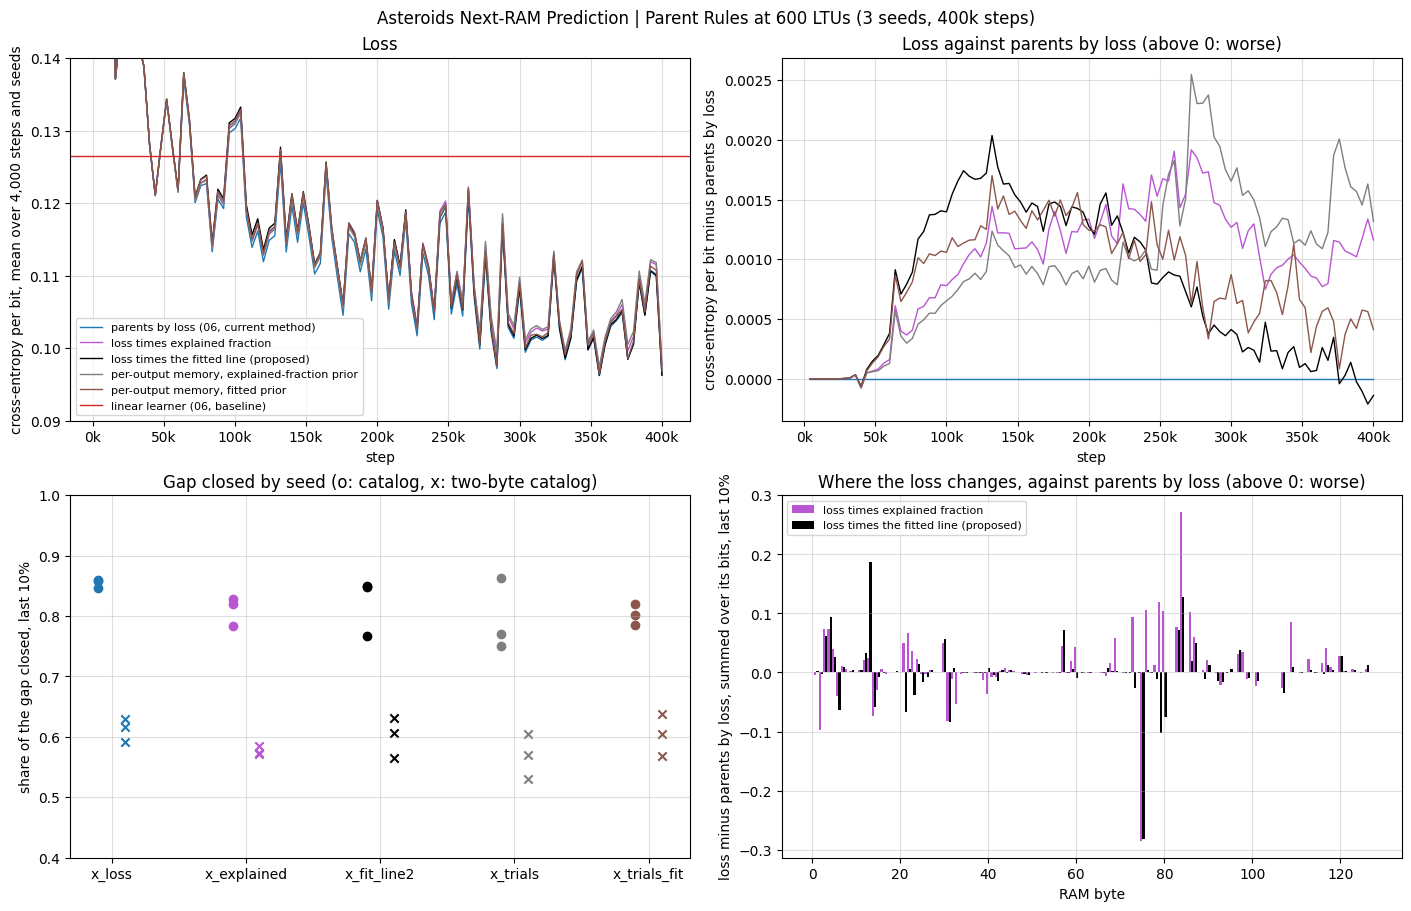

In [4]:
steps = LOG_EVERY * np.arange(1, N_STEPS // LOG_EVERY + 1)
fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout='constrained')
for i, (label, name, color) in enumerate(RUNS):
    s = scores[name].mean(0)
    axes[0, 0].plot(steps, s[:, :-1].mean(1), color=color, lw=1, label=label)
    axes[0, 1].plot(steps, s[:, :-1].mean(1) - scores['x_loss'].mean(0)[:, :-1].mean(1), color=color, lw=1, label=label)
    _, gap, gap2 = summary[name]
    axes[1, 0].scatter(np.full(3, i) - 0.1, gap, color=color, marker='o', label=label)
    axes[1, 0].scatter(np.full(3, i) + 0.1, gap2, color=color, marker='x')
axes[0, 0].axhline(LINEAR_06[0], color='tab:red', lw=1, label='linear learner (06, baseline)')
for ax in axes[0]:
    ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1000:.0f}k')
    ax.set_xlabel('step')
axes[0, 0].set(ylim=(0.09, 0.14), ylabel=f'cross-entropy per bit, mean over {LOG_EVERY:,} steps and seeds',
               title='Loss')
axes[0, 1].set(ylabel='cross-entropy per bit minus parents by loss', title='Loss against parents by loss (above 0: worse)')
axes[1, 0].set(xticks=range(len(RUNS)), xticklabels=[name for _, name, _ in RUNS], ylim=(0.4, 1.0),
               ylabel='share of the gap closed, last 10%', title='Gap closed by seed (o: catalog, x: two-byte catalog)')
reference = summary['x_loss'][0].mean(0)
for label, name, color in RUNS[1:3]:
    change = (summary[name][0].mean(0) - reference).reshape(128, 8).sum(1)
    axes[1, 1].bar(np.arange(128) + (0.25 if 'fitted' in label else -0.25), change, width=0.5, color=color, label=label)
axes[1, 1].set(xlabel='RAM byte', ylabel='loss minus parents by loss, summed over its bits, last 10%',
               title='Where the loss changes, against parents by loss (above 0: worse)')
for ax in axes.flat:
    ax.grid(alpha=0.4)
axes[0, 0].legend(fontsize=8)
axes[1, 1].legend(fontsize=8)
fig.suptitle('Asteroids Next-RAM Prediction | Parent Rules at 600 LTUs (3 seeds, 400k steps)')
plt.show()

## Results

- **All five rules end within about 1.5% of each other in loss**: parents by loss 0.1041 per bit, 81.5% of varying
  bytes right, 85% of the catalog gap closed (86 / 85 / 86); loss times explained fraction 0.1052, 81.0%, 81%; loss
  times the fitted line 0.1042, 81.4%, 82% (85 / 85 / 77); the two with per-output memory 0.1057 and 0.1046. The
  differences are far smaller than the swings the data's own changes cause over time (top left).
- **Over time** (top right), the fitted line is worse than parents by loss while it is still close to where it
  starts, loss times explained fraction (by up to 0.002 per bit around 100–150k steps), level with it by about 300k,
  and slightly better at the end. Loss times explained fraction stays about 0.001 worse throughout.
- **By byte** (bottom right), both new rules do much better on byte 75 (0.28 nats per step less) and worse on bytes
  4–5 and 84 (by 0.27 nats for explained fraction, 0.13 for the fitted line); the fitted line is also worse on
  byte 13.